# Gas Intelligence 360° · Etapa 1: Importação e tratamento (Google Colab)

**Objetivo:** importar as 7 bases brutas de uma distribuidora de gás fictícia, diagnosticar a qualidade dos dados,
aplicar regras de tratamento documentadas e exportar cópias tratadas para alimentar o Data Warehouse (Etapa 2).

> ⚠️ Dados 100% sintéticos, criados para estudo. A base bruta **nunca é alterada**: todo tratamento gera cópias em `data/processed/`.

| Base | Conteúdo | Granularidade |
|---|---|---|
| `clientes` | Cadastro de clientes | 1 linha por cliente |
| `contratos` | Contratos de fornecimento | 1 linha por contrato |
| `consumo` | Leituras de medidor | contrato × competência |
| `faturas` | Faturamento mensal | contrato × competência |
| `pagamentos` | Pagamentos recebidos | 1 linha por pagamento |
| `operacoes` | Volume distribuído × medido e custo | cidade × competência |
| `ocorrencias` | Chamados técnicos | 1 linha por ocorrência |

## 1. Preparando o ambiente

No Colab, a célula abaixo clona este repositório e entra na pasta do projeto. Rodando localmente, ela apenas localiza a raiz do projeto.

💡 **Alternativa:** para subir os arquivos manualmente no Colab, use
`from google.colab import files; files.upload()` e ajuste a variável `RAW`.

In [1]:
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/Brithysetubal/gas-intelligence-360.git"

if "google.colab" in sys.modules:
    if not Path("gas-intelligence-360").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL], check=True)
    os.chdir("gas-intelligence-360")
else:
    while not Path("data/raw").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")

RAW, PROC = Path("data/raw"), Path("data/processed")
PROC.mkdir(parents=True, exist_ok=True)
print("Pasta do projeto:", Path.cwd().name)
print("Arquivos brutos:", sorted(p.name for p in RAW.glob("*.csv")))

Pasta do projeto: gas-intelligence-360
Arquivos brutos: ['clientes.csv', 'consumo.csv', 'contratos.csv', 'faturas.csv', 'ocorrencias.csv', 'operacoes.csv', 'pagamentos.csv']


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

# Data em que a base foi extraída: qualquer pagamento depois dela é inconsistente
DATA_REFERENCIA = pd.Timestamp("2026-11-10")

## 2. Importação

Todas as colunas são lidas como texto (`dtype=str`) para que nenhum valor seja "corrigido" silenciosamente pelo pandas.
A conversão de tipos acontece depois, de forma explícita.

In [3]:
TABELAS = ["clientes", "contratos", "consumo", "faturas", "pagamentos", "operacoes", "ocorrencias"]
bruto = {t: pd.read_csv(RAW / f"{t}.csv", dtype=str, encoding="utf-8-sig") for t in TABELAS}

pd.DataFrame({t: {"linhas": len(df), "colunas": df.shape[1]} for t, df in bruto.items()}).T

,linhas,colunas
clientes,301,6
contratos,300,5
consumo,10201,6
faturas,10201,6
pagamentos,9108,5
operacoes,204,6
ocorrencias,150,6


## 3. Diagnóstico de qualidade

### 3.1 Duplicatas e nulos

In [4]:
def perfil(nome, df):
    chave = df.columns[0]
    return {
        "tabela": nome,
        "linhas": len(df),
        "linhas_duplicadas": int(df.duplicated().sum()),
        "chave_duplicada": int(df[chave].duplicated().sum()),
        "células_nulas": int(df.isna().sum().sum()),
        "colunas_com_nulo": ", ".join(df.columns[df.isna().any()]) or "-",
    }

diagnostico = pd.DataFrame([perfil(t, df) for t, df in bruto.items()]).set_index("tabela")
diagnostico

,linhas,linhas_duplicadas,chave_duplicada,células_nulas,colunas_com_nulo
tabela,,,,,
clientes,301,1,1,2,"cidade, segmento"
contratos,300,0,0,0,-
consumo,10201,1,1,1,volume_m3
faturas,10201,1,1,68,valor_fatura_brl
pagamentos,9108,0,0,0,-
operacoes,204,0,0,0,-
ocorrencias,150,0,0,0,-


### 3.2 Integridade referencial (chaves órfãs)

Toda chave estrangeira precisa existir na tabela de origem. Quando não existe, temos um registro **órfão**.

In [5]:
def orfaos(filho, col, pai, col_pai=None):
    col_pai = col_pai or col
    mask = ~bruto[filho][col].isin(bruto[pai][col_pai])
    return bruto[filho].loc[mask, col].unique().tolist()

checagens = {
    "contratos.cliente_id → clientes": orfaos("contratos", "cliente_id", "clientes"),
    "consumo.contrato_id → contratos": orfaos("consumo", "contrato_id", "contratos"),
    "faturas.contrato_id → contratos": orfaos("faturas", "contrato_id", "contratos"),
    "pagamentos.fatura_id → faturas": orfaos("pagamentos", "fatura_id", "faturas"),
    "ocorrencias.contrato_id → contratos": orfaos("ocorrencias", "contrato_id", "contratos"),
}
for regra, chaves in checagens.items():
    print(f"{'❌' if chaves else '✅'} {regra}: {chaves or 'ok'}")

❌ contratos.cliente_id → clientes: ['CLI9999']
✅ consumo.contrato_id → contratos: ok
✅ faturas.contrato_id → contratos: ok
❌ pagamentos.fatura_id → faturas: ['FAT999999']
✅ ocorrencias.contrato_id → contratos: ok


### 3.3 Valores numéricos fora do esperado

In [6]:
consumo_num = pd.to_numeric(bruto["consumo"]["volume_m3"])
faturas_num = pd.to_numeric(bruto["faturas"]["valor_fatura_brl"])
pag_num = pd.to_numeric(bruto["pagamentos"]["valor_pago_brl"])
pag_data = pd.to_datetime(bruto["pagamentos"]["data_pagamento"])

print("Leituras com volume negativo:", (consumo_num < 0).sum())
print("Leituras sem volume:         ", consumo_num.isna().sum())
print("Faturas sem valor:           ", faturas_num.isna().sum())
print("Faturas com valor zero:      ", (faturas_num == 0).sum())
print("Pagamentos com valor zero:   ", (pag_num == 0).sum())
print("Pagamentos com data futura:  ", (pag_data > DATA_REFERENCIA).sum())

Leituras com volume negativo: 34
Leituras sem volume:          1
Faturas sem valor:            68
Faturas com valor zero:       34
Pagamentos com valor zero:    90
Pagamentos com data futura:   142


Volumes muito altos **não são** necessariamente erro: o consumo depende do segmento do cliente.
O gráfico (em escala log) mostra três faixas bem separadas, então não tratamos esses valores como outliers.

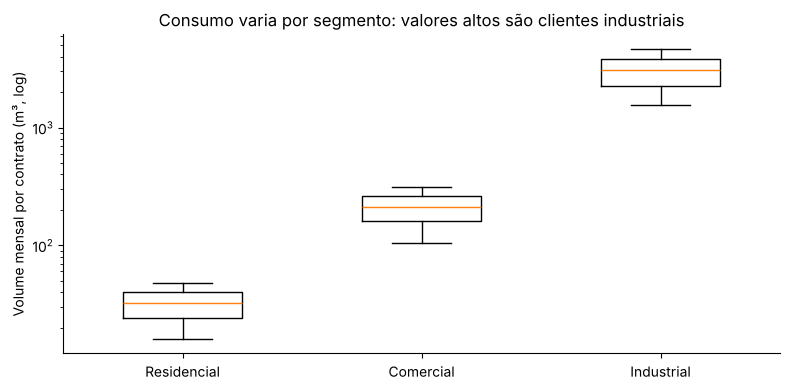

In [7]:
seg = bruto["contratos"].merge(bruto["clientes"].drop_duplicates(), on="cliente_id", how="left")[["contrato_id", "segmento"]]
vol = bruto["consumo"].assign(volume_m3=consumo_num).merge(seg, on="contrato_id")
vol = vol[vol.volume_m3 > 0]

fig, ax = plt.subplots(figsize=(8, 4))
ordem = ["Residencial", "Comercial", "Industrial"]
ax.boxplot([vol.loc[vol.segmento == s, "volume_m3"] for s in ordem], widths=0.5)
ax.set_xticks([1, 2, 3], ordem)
ax.set_yscale("log")
ax.set_ylabel("Volume mensal por contrato (m³, log)")
ax.set_title("Consumo varia por segmento: valores altos são clientes industriais")
plt.tight_layout(); plt.show()

### 3.4 Descobrindo a regra de tarifa

Dividindo o valor da fatura pelo volume, encontramos uma **tarifa fixa por segmento**. Essa regra será usada para
recalcular faturas sem valor e para inferir o segmento de clientes com cadastro incompleto.

In [8]:
fat = bruto["faturas"].assign(valor=faturas_num).merge(
    bruto["consumo"].drop_duplicates().assign(volume=consumo_num), on=["contrato_id", "competencia"]).merge(seg, on="contrato_id")
fat = fat[(fat.volume > 0) & (fat.valor > 0)]
TARIFA = (fat.valor / fat.volume).round(2).groupby(fat.segmento).median().to_dict()
TARIFA

{'Comercial': 5.4, 'Industrial': 4.3, 'Residencial': 6.2}

## 4. Regras de tratamento

| # | Tabela | Problema | Regra aplicada |
|---|---|---|---|
| 1 | todas | Linhas duplicadas | Remover duplicata exata |
| 2 | clientes | `segmento` nulo | Inferir pela tarifa praticada nas faturas do cliente |
| 3 | clientes | `cidade` nula | Preencher com `Não informado` |
| 4 | contratos | Cliente inexistente (CLI9999) | Manter contrato e marcar `cliente_orfao`; no DW vai para o membro "Desconhecido" |
| 5 | consumo | Volume negativo | Invalidar o volume (vira nulo) e marcar `status_leitura` |
| 6 | consumo | Volume nulo | Marcar `status_leitura = Ausente` |
| 7 | faturas | Valor nulo | Recalcular: volume × tarifa do segmento, marcar `Recalculada` |
| 8 | faturas | Valor zero por leitura inválida | Manter e marcar `Zerada (leitura inválida)` |
| 9 | pagamentos | Fatura inexistente, data futura ou valor zero | Mover para **quarentena** (não entram como receita) |

In [9]:
log = []  # trilha de auditoria: o que foi feito, em qual tabela e quantas linhas

def registrar(tabela, regra, linhas):
    log.append({"tabela": tabela, "regra": regra, "linhas_afetadas": int(linhas)})

def deduplicar(nome):
    df = bruto[nome].copy()
    n = df.duplicated().sum()
    registrar(nome, "Remoção de linhas duplicadas", n)
    return df.drop_duplicates().reset_index(drop=True)

### 4.1 Consumo

In [10]:
consumo = deduplicar("consumo")
consumo["volume_m3"] = pd.to_numeric(consumo["volume_m3"])
consumo["status_leitura"] = np.select(
    [consumo.volume_m3.isna(), consumo.volume_m3 < 0], ["Ausente", "Negativa (invalidada)"], "Válida")
registrar("consumo", "Volume nulo marcado como Ausente", (consumo.status_leitura == "Ausente").sum())
registrar("consumo", "Volume negativo invalidado", (consumo.status_leitura == "Negativa (invalidada)").sum())
consumo.loc[consumo.volume_m3 < 0, "volume_m3"] = np.nan
consumo = consumo.drop(columns="unidade")
consumo.status_leitura.value_counts()

status_leitura
Válida                   10165
Negativa (invalidada)       34
Ausente                      1
Name: count, dtype: int64

### 4.2 Clientes e contratos

In [11]:
clientes = deduplicar("clientes")
clientes["data_cadastro"] = pd.to_datetime(clientes["data_cadastro"])

# Inferência de segmento pela tarifa observada
tarifa_para_segmento = {v: k for k, v in TARIFA.items()}
fat_cli = (bruto["faturas"].assign(valor=faturas_num)
           .merge(consumo[["contrato_id", "competencia", "volume_m3"]], on=["contrato_id", "competencia"])
           .merge(bruto["contratos"][["contrato_id", "cliente_id"]], on="contrato_id"))
fat_cli = fat_cli[(fat_cli.valor > 0) & (fat_cli.volume_m3 > 0)]
tarifa_cliente = (fat_cli.valor / fat_cli.volume_m3).round(2).groupby(fat_cli.cliente_id).median()

sem_seg = clientes.segmento.isna()
clientes["segmento_inferido"] = sem_seg
clientes.loc[sem_seg, "segmento"] = clientes.loc[sem_seg, "cliente_id"].map(tarifa_cliente).map(tarifa_para_segmento)
registrar("clientes", "Segmento nulo inferido pela tarifa", sem_seg.sum())

sem_cidade = clientes.cidade.isna()
clientes.loc[sem_cidade, "cidade"] = "Não informado"
registrar("clientes", "Cidade nula preenchida com 'Não informado'", sem_cidade.sum())

contratos = deduplicar("contratos")
contratos["data_inicio"] = pd.to_datetime(contratos["data_inicio"])
contratos["cliente_orfao"] = ~contratos.cliente_id.isin(clientes.cliente_id)
registrar("contratos", "Contrato com cliente inexistente marcado", contratos.cliente_orfao.sum())

clientes[clientes.segmento_inferido | (clientes.cidade == "Não informado")]

,cliente_id,nome_ficticio,cidade,segmento,data_cadastro,status_cliente,segmento_inferido
13,CLI0014,Cliente Fictício 0014,Não informado,Comercial,2023-04-22,Ativo,False
41,CLI0042,Cliente Fictício 0042,São Gonçalo,Residencial,2024-05-16,Ativo,True


### 4.3 Faturas

In [12]:
faturas = deduplicar("faturas")
faturas["valor_fatura_brl"] = pd.to_numeric(faturas["valor_fatura_brl"])
faturas["data_vencimento"] = pd.to_datetime(faturas["data_vencimento"])

segmento_contrato = contratos.merge(clientes[["cliente_id", "segmento"]], on="cliente_id", how="left")
# contrato órfão: segmento deduzido pela tarifa das próprias faturas
seg_map = segmento_contrato.set_index("contrato_id")["segmento"]
for c in seg_map[seg_map.isna()].index:
    f = faturas[faturas.contrato_id == c].merge(consumo, on=["contrato_id", "competencia"])
    f = f[(f.valor_fatura_brl > 0) & (f.volume_m3 > 0)]
    seg_map[c] = tarifa_para_segmento[(f.valor_fatura_brl / f.volume_m3).round(2).median()]

faturas = faturas.merge(consumo[["contrato_id", "competencia", "volume_m3"]], on=["contrato_id", "competencia"], how="left")
faturas["tarifa_brl_m3"] = faturas.contrato_id.map(seg_map).map(TARIFA)

nulas = faturas.valor_fatura_brl.isna() & faturas.volume_m3.notna()
faturas.loc[nulas, "valor_fatura_brl"] = (faturas.volume_m3 * faturas.tarifa_brl_m3).round(2)
faturas["status_fatura"] = np.select(
    [nulas, faturas.valor_fatura_brl == 0], ["Recalculada", "Zerada (leitura inválida)"], "Original")
registrar("faturas", "Valor nulo recalculado (volume × tarifa)", nulas.sum())
registrar("faturas", "Fatura zerada por leitura inválida marcada", (faturas.status_fatura == "Zerada (leitura inválida)").sum())
faturas = faturas.drop(columns=["volume_m3", "moeda"])
faturas.status_fatura.value_counts()

status_fatura
Original                     10098
Recalculada                     68
Zerada (leitura inválida)       34
Name: count, dtype: int64

### 4.4 Pagamentos (com quarentena)

In [13]:
pagamentos = deduplicar("pagamentos")
pagamentos["valor_pago_brl"] = pd.to_numeric(pagamentos["valor_pago_brl"])
pagamentos["data_pagamento"] = pd.to_datetime(pagamentos["data_pagamento"])

pagamentos["motivo_quarentena"] = np.select(
    [~pagamentos.fatura_id.isin(faturas.fatura_id),
     pagamentos.data_pagamento > DATA_REFERENCIA,
     pagamentos.valor_pago_brl == 0],
    ["Fatura inexistente", "Data futura", "Valor zero"], None)

quarentena = pagamentos[pagamentos.motivo_quarentena.notna()]
pagamentos = pagamentos[pagamentos.motivo_quarentena.isna()].drop(columns="motivo_quarentena")
for motivo, n in quarentena.motivo_quarentena.value_counts().items():
    registrar("pagamentos", f"Quarentena: {motivo}", n)
quarentena.motivo_quarentena.value_counts()

motivo_quarentena
Data futura           142
Valor zero             89
Fatura inexistente      1
Name: count, dtype: int64

### 4.5 Operações e ocorrências

Estas bases vieram íntegras; apenas convertemos tipos e criamos o indicador de **perda técnica** (gás distribuído que não foi medido).

In [14]:
operacoes = deduplicar("operacoes")
for c in ["volume_distribuido_m3", "volume_medido_m3", "custo_operacional_brl"]:
    operacoes[c] = pd.to_numeric(operacoes[c])
operacoes["perda_m3"] = (operacoes.volume_distribuido_m3 - operacoes.volume_medido_m3).round(2)
operacoes["perda_pct"] = (operacoes.perda_m3 / operacoes.volume_distribuido_m3).round(4)

ocorrencias = deduplicar("ocorrencias")
ocorrencias["data_ocorrencia"] = pd.to_datetime(ocorrencias["data_ocorrencia"])
operacoes.head()

,operacao_id,competencia,cidade,volume_distribuido_m3,volume_medido_m3,custo_operacional_brl,perda_m3,perda_pct
0,OPE00001,2024-01,Rio de Janeiro,14216.27,12150.31,38851.93,2065.96,0.1453
1,OPE00002,2024-01,Niterói,14408.50,13368.48,31069.11,1040.02,0.0722
2,OPE00003,2024-01,Duque de Caxias,8481.33,8043.99,23564.86,437.34,0.0516
3,OPE00004,2024-01,Nova Iguaçu,9872.84,8460.03,20568.62,1412.81,0.1431
4,OPE00005,2024-01,São Gonçalo,12716.40,11616.51,37461.37,1099.89,0.0865


## 5. Relatório de qualidade e exportação

In [15]:
relatorio = pd.DataFrame(log).query("linhas_afetadas > 0").reset_index(drop=True)
relatorio

,tabela,regra,linhas_afetadas
0,consumo,Remoção de linhas duplicadas,1
1,consumo,Volume nulo marcado como Ausente,1
2,consumo,Volume negativo invalidado,34
3,clientes,Remoção de linhas duplicadas,1
4,clientes,Segmento nulo inferido pela tarifa,1
5,clientes,Cidade nula preenchida com 'Não informado',1
6,contratos,Contrato com cliente inexistente marcado,1
7,faturas,Remoção de linhas duplicadas,1
8,faturas,Valor nulo recalculado (volume × tarifa),68
9,faturas,Fatura zerada por leitura inválida marcada,34


In [16]:
tratadas = {"clientes": clientes, "contratos": contratos, "consumo": consumo, "faturas": faturas,
            "pagamentos": pagamentos, "operacoes": operacoes, "ocorrencias": ocorrencias}
for nome, df in tratadas.items():
    df.to_csv(PROC / f"{nome}_tratado.csv", index=False, date_format="%Y-%m-%d")
quarentena.to_csv(PROC / "pagamentos_quarentena.csv", index=False, date_format="%Y-%m-%d")
relatorio.to_csv(PROC / "log_qualidade.csv", index=False)

pd.DataFrame({n: {"bruto": len(bruto[n]), "tratado": len(df)} for n, df in tratadas.items()}).T

,bruto,tratado
clientes,301,300
contratos,300,300
consumo,10201,10200
faturas,10201,10200
pagamentos,9108,8876
operacoes,204,204
ocorrencias,150,150


✅ Bases tratadas salvas em `data/processed/`. Próxima etapa: **[02 · Data Warehouse](../02_data_warehouse/02_construcao_dw.ipynb)**.